In [3]:
import pandas as pd
df = pd.read_csv("../data/Car_Insurance_Claim.csv")
df.head(5)

,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


### To install all python modules run this command 'pip install -r requirements.txt'

#Phase 1 - Business Understanding

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/Car_Insurance_Claim.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Matplotlib is building the font cache; this may take a moment.


Rows: 10000
Columns: 19


,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


## 1.1 Context and problem

This project looks at car insurance. When a Insurance company sells a policy, They have to guess how likly a customer is likly to make a claim. If it guess too low it can lose money from paying out claims but if it guess too high for a customer , The customer may go somewhere else and not get insurance of the insurance company and go looking else where

The Specific problem we have is :  **Using information the insurer has when the policy starts(driver details,vehicle details,driving history and age),Also if we can predict whether a customer will make a claim or not ?**

The dataset im using is a Car insurance Claim dataset from kaggle , It has over 10,000 customer and 19 columns. The 'OUTCOME' column shows if the customer has made a claim or not . 1 being shown as 'has made a claim' and 0 shown as 'Not made a claim'


In [ ]:
# 0 no claim, 1 Has a claim
counts = df["OUTCOME"].value_counts()
percent = df["OUTCOME"].value_counts(normalize=True) * 100

pd.DataFrame({"Customers": counts, "Percent": percent.round(1)})

,Customers,Percent
OUTCOME,,
0.0,6867,68.7
1.0,3133,31.3


The table above shows us that 31.3% of customers have made a claim and the other 68.7% did not. So this shows that claims are in the smaller group 


## 1.2 Stakeholders and users

|Who | Role |
|---|---|
|Customer| Supply data and are affected by the result  as this can change their price or weather they can get insured or not |
|Pricing team| These are the main users , they will use the prediction to help set the risk leve and price of the policy given |
|Claims Department| Can use it to plan for how many claims to expect |
|Company managment|Want fewer unexpected losses and fair consistent pricing |

## 1.3 Business Objective
The business would want to find the higher risk customers before a policy is sold to them so it can price them correctly and keep the price consistent between customers. This model would support the underwriters decision, not replace them

## 1.4 Analytics objective
This is a binary Classification task. The taget is 'OUTCOME' (0 = no claim, 1 = has a claim). The inputs are in other columns
The model should give a prediction 'claim or no claim' and a probability of claiming so customers can be ranked as low risk or high risk
This will allow the insures to give prices appropriatly to the given customers



## 1.5 Success criteria

A model that always predicts 'no claim' would already be 68.7% accurate, so accuracy on its own is not a good mesaure here

**Technical criteria**
- Clearly beat the 68.7% baseline.
- Recall for the claim class (1) of at least 0.70, so most customers who do claim are caught.
- ROC-AUC of at least 0.80 on the test set.
- Similar results on the training and test sets, to show the model is not overfitting.

**Practical criteria**
- An underwriter can understand which factors drive the prediction (e.g. past accidents, driving experience, mileage).
- The model does not use race, and its results are checked so it does not treat groups unfairly.
- The results are clear enough to support a pricing decision, not just a number.


## 1.6 Contraints and Assumptions

## Constraints

|Area|Constraint| Effect on the Project|
|----|----|---|
|Data|One Kaggle file ,License is also unknown so no way of knowing who the publisher is | Results may not be a match to real insurer|
|Privacy| Contains personal Details such as driving offences, gender and race | I will treat it as personal data and only use it for this project|
|Scope|The model predicts claim or no claim only| It does not preict claim cost or actual price|

## Assumptions
|Assumption| Result of being wrong |
|----|----|
|OUTCOME means a claim during the policy period| The model would answer differnt questions than in 1.1 |
|Inputs (PAST_ACCIDENTS,SPEEDING_VIOLATIONS,DIOS) are all known when the policy starts|the model would be expierencing data leakage and results would look better than what they realisiticaly are |
|The Rows are a fair samply of th real customers| Patterns that are found may not hold relaiabilty to a real insurer |
|Missing columns (CREDIT_SCORE,ANNUAL_MILEAGE) are missing at random|filling these in could add bias . I will chek this in PHASE 2|




In [ ]:
# Columns with missing values
missing = df.isnull().sum()

print("\n\n")
print(df["RACE"].value_counts())
print(df["GENDER"].value_counts())




RACE
majority    9012
minority     988
Name: count, dtype: int64
GENDER
female    5010
male      4990
Name: count, dtype: int64


## 1.7 Initial project plan

| CRISP-DM phase | What I will do |
|---|---|
| 1. Business Understanding | Define the problem, stakeholders, objectives and success criteria  |
| 2. Data Understanding | Explore the data: size, data types, missing values, class balance, charts of each feature against `OUTCOME` |
| 3. Data Preparation | Fill or remove missing values, drop `ID` and `RACE`, encode categories, split into train and test sets |
| 4. Modelling | Start with Descion Tree and Random Forrest |
| 5. Evaluation | Compare models using recall, precision, F1, ROC-AUC and a confusion matrix, against the success criteria in 1.5 |
| 6. Deployment | Explain how the model could be used by underwriters, its limits, and next steps |

# Phase 2 : Data Understanding

## Initial Data Collection report

- **Source :** Kaggle - https://www.kaggle.com/datasets/sagnik1511/car-insurance-data
- **Publisher :** Sagnik Roy
- **Date Accessed :** 2nd November 2026
- **License :** License is Unknown
- **How Data was Collected :** Data was Collected Through car insurance companies and some of the data is generated by the author its self
- **Population, Time and Place** There is over 10,000 Customers in the dataSet but as for Dates none are given by the author but has been updated last 5 years ago, Data is in the US as PostCodes determine they are 
- **Grouping and Rounding :** Age,Driving expierience and income are in given groups and not exact valuesm Annual Milage is rounded to teh nearest 1,000.
- **Files :** This is in 1 file : 'Car_Insurance_Claim.csv' 





In [ ]:
df.info()

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Lowest and highest value for each number column
df.describe().loc[["min", "max"]].round(2)

#This will show the Data Types of each of these
for col in ["AGE", "GENDER", "RACE", "DRIVING_EXPERIENCE", "EDUCATION", "INCOME", "VEHICLE_YEAR", "VEHICLE_TYPE"]:
    print(col, ":", df[col].unique())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   AGE                  10000 non-null  str    
 2   GENDER               10000 non-null  str    
 3   RACE                 10000 non-null  str    
 4   DRIVING_EXPERIENCE   10000 non-null  str    
 5   EDUCATION            10000 non-null  str    
 6   INCOME               10000 non-null  str    
 7   CREDIT_SCORE         9018 non-null   float64
 8   VEHICLE_OWNERSHIP    10000 non-null  float64
 9   VEHICLE_YEAR         10000 non-null  str    
 10  MARRIED              10000 non-null  float64
 11  CHILDREN             10000 non-null  float64
 12  POSTAL_CODE          10000 non-null  int64  
 13  ANNUAL_MILEAGE       9043 non-null   float64
 14  VEHICLE_TYPE         10000 non-null  str    
 15  SPEEDING_VIOLATIONS  10000 non-null  int64  
 16

## 2.2 Data Description Report

This dataset has over 10,000 Rows and 19 columns , Each row is only 1 customer 'CREDIT_SCORE' and 'ANNUAL_MILEAGE' have fewer than 10,000 values so some have missing data

### Data dictionary

| Column | Meaning | Data type | Kind of variable | Unit | Valid values / range | Role |
|---|---|---|---|---|---|---|
| ID | Customer ID | int64 | Identifier | – | Unique for every customer | Identifier – drop |
| AGE | Age group | str | Category (ordered) | Years, grouped | 16-25, 26-39, 40-64, 65+ | Input |
| GENDER | Gender | str | Category (unordered) | – | female, male | Input |
| RACE | Race group | str | Category (unordered) | – | majority, minority | Sensitive – drop |
| DRIVING_EXPERIENCE | Years driving | str | Category (ordered) | Years, grouped | 0-9y, 10-19y, 20-29y, 30y+ | Input |
| EDUCATION | Highest education | str | Category (ordered) | – | none, high school, university | Input |
| INCOME | Income group | str | Category (ordered) | – | poverty, working class, middle class, upper class | Input |
| CREDIT_SCORE | Credit score | float64 | Number | Score (scale not explained) | 0.05 to 0.96 | Input |
| VEHICLE_OWNERSHIP | Owns the car | float64 | Yes/No | – | 0 = no, 1 = yes | Input |
| VEHICLE_YEAR | When the car was made | str | Category (ordered) | – | before 2015, after 2015 | Input |
| MARRIED | Married | float64 | Yes/No | – | 0 = no, 1 = yes | Input |
| CHILDREN | Has children | float64 | Yes/No | – | 0 = no, 1 = yes | Input |
| POSTAL_CODE | Area code | int64 | Category (unordered) | – | 10238, 21217, 32765, 92101 | Input – check |
| ANNUAL_MILEAGE | Distance driven per year | float64 | Number | Miles (assumed) | 2,000 to 22,000 | Input |
| VEHICLE_TYPE | Type of car | str | Category (unordered) | – | sedan, sports car | Input |
| SPEEDING_VIOLATIONS | Speeding fines | int64 | Count | Number of fines | 0 to 22 | Input |
| DUIS | Drink-driving offences | int64 | Count | Number of offences | 0 to 6 | Input |
| PAST_ACCIDENTS | Past accidents | int64 | Count | Number of accidents | 0 to 15 | Input |
| OUTCOME | Made a claim | float64 | Yes/No | – | 0 = no claim, 1 = claim | **Target** |

**Ordered** categories have a natural order (16-25 is younger than 65+). **Unordered** categories are just labels (female and male). This decides how each column is turned into numbers in Data Preparation.


## Identifiersm Inputs and Target

- **Identifier :** ID is unique for each customer and has no link or corearlation to having a claim so that would be dropped
- **Target** 'OUTCOME', Weather the customer made a claim (1) or customer did not make a claim (0)
- **Candinate Inputs :* 17 columns are all the things a insurer would know when a policy starts* 



### How the variables were measured
- `AGE`, `DRIVING_EXPERIENCE` and `INCOME` are given in groups, not exact values, so some detail is lost.
- `CREDIT_SCORE` is between 0 and 1, but the dataset doesn't explain how it was calculated.
- `ANNUAL_MILEAGE` is rounded to the nearest 1,000. The unit isn't stated. it could be asssumed as in Miles as some of the Postal Codes were American
- `VEHICLE_OWNERSHIP`, `MARRIED`, `CHILDREN` and `OUTCOME` only hold 0 or 1 but are stored as decimals.
- `POSTAL_CODE` is stored as a number but is really a category. A bigger code doesn't mean anything.

In [ ]:
df.info()

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Lowest and highest value for each number column
df.describe().loc[["min", "max"]].round(2)



#This will show the Data Types of each of these
for col in ["AGE", "GENDER", "RACE", "DRIVING_EXPERIENCE", "EDUCATION", "INCOME", "VEHICLE_YEAR", "VEHICLE_TYPE"]:
    print(col, ":", df[col].unique())


NameError: name 'df' is not defined

In [ ]:
df.describe().round(2)

,ID,CREDIT_SCORE,VEHICLE_OWNERSHIP,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
count,10000.00,9018.00,10000.00,10000.0,10000.00,10000.00,9043.00,10000.00,10000.00,10000.00,10000.00
mean,500521.91,0.52,0.70,0.5,0.69,19864.55,11697.00,1.48,0.24,1.06,0.31
std,290030.77,0.14,0.46,0.5,0.46,18915.61,2818.43,2.24,0.55,1.65,0.46
min,101.00,0.05,0.00,0.0,0.00,10238.00,2000.00,0.00,0.00,0.00,0.00
25%,249638.50,0.42,0.00,0.0,0.00,10238.00,10000.00,0.00,0.00,0.00,0.00
50%,501777.00,0.53,1.00,0.0,1.00,10238.00,12000.00,0.00,0.00,0.00,0.00
75%,753974.50,0.62,1.00,1.0,1.00,32765.00,14000.00,2.00,0.00,2.00,1.00
max,999976.00,0.96,1.00,1.0,1.00,92101.00,22000.00,22.00,6.00,15.00,1.00


## 2.3 Data Exploration Report

In this sections I will be looking at how each column relates to the Column 'OUTCOME'. Each step will start with a question so the chart are linked to what i generally want to find out. Any patterns that i find will be links in the data , not 100% proof that on thing causes another


### Question : Which groups of customer Claim more ? 
**why question this ?:** I want to see which categories have a higher claims rate than on average. These are likely to be useful inputs that i can integrate into my model


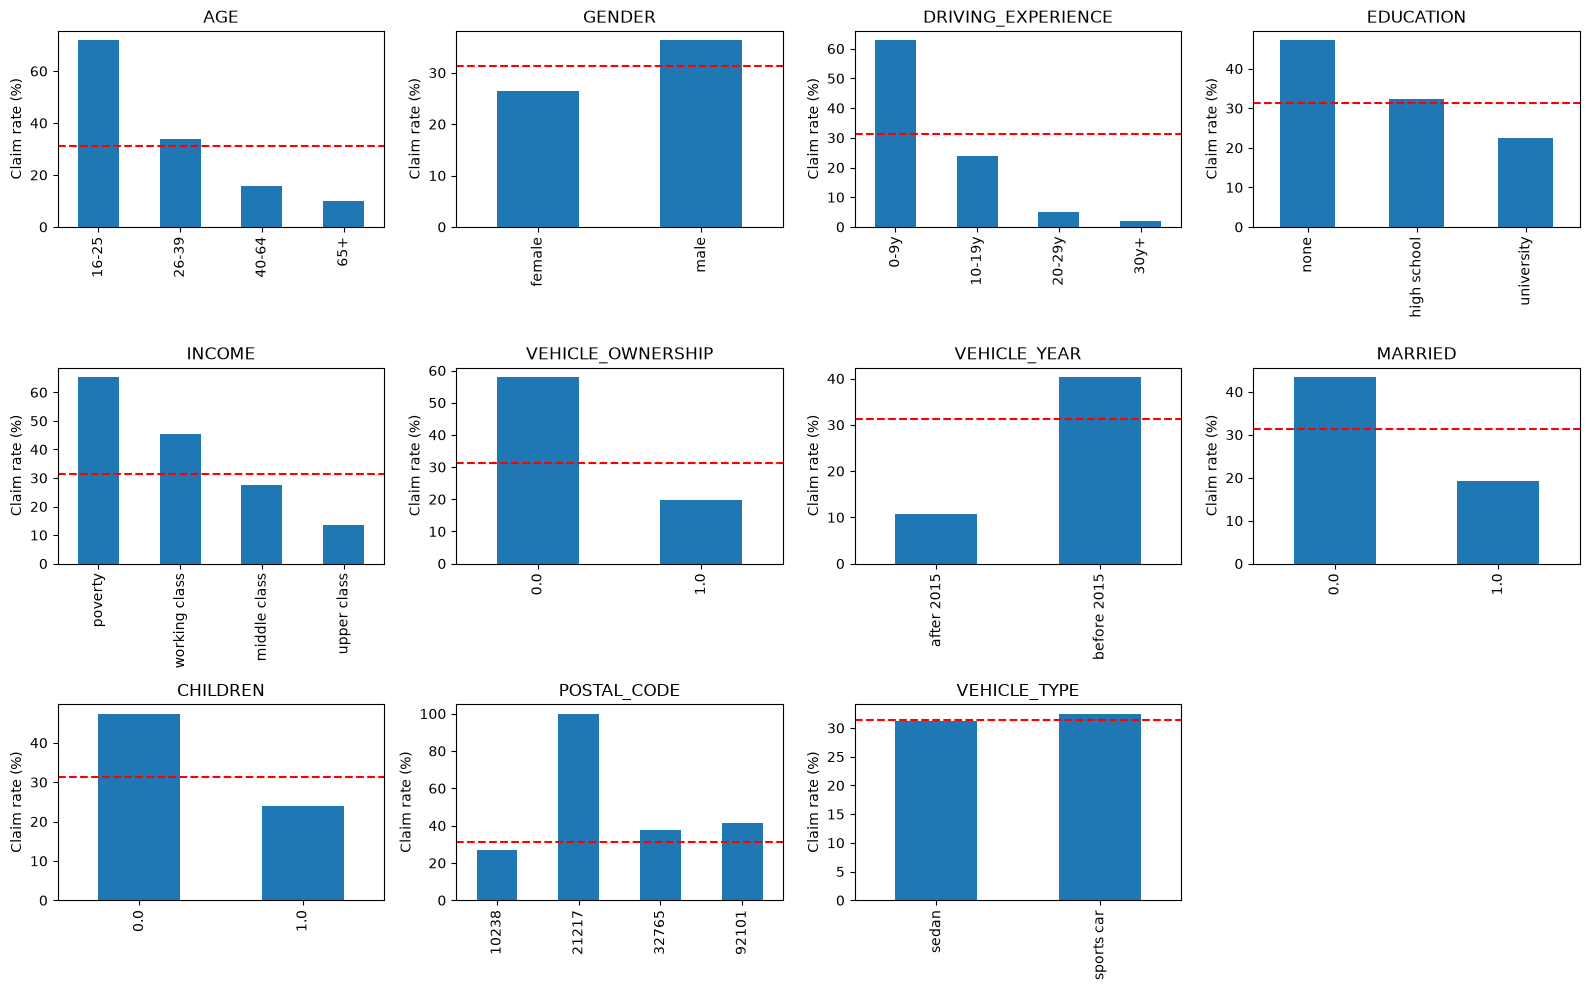

In [ ]:
# The category columns I want to compare against OUTCOME
import pandas as pd
import matplotlib.pyplot as plt


category_columns = ["AGE", "GENDER", "DRIVING_EXPERIENCE", "EDUCATION", "INCOME",
                    "VEHICLE_OWNERSHIP", "VEHICLE_YEAR", "MARRIED", "CHILDREN",
                    "POSTAL_CODE", "VEHICLE_TYPE"]

overall_rate = df["OUTCOME"].mean() * 100

# Make a grid of 3 rows x 4 columns = 12 empty charts
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()  

for i in range(len(category_columns)):
    column = category_columns[i]
    chart = axes[i]

    

    claim_rate = df.groupby(column)["OUTCOME"].mean() * 100


    if column == "EDUCATION":
        claim_rate = claim_rate[["none", "high school", "university"]]
    if column == "INCOME":
        claim_rate = claim_rate[["poverty", "working class", "middle class", "upper class"]]

    claim_rate.plot(kind="bar", ax=chart)
    chart.axhline(overall_rate, color="red", linestyle="--")   # overall rate line
    chart.set_title(column)
    chart.set_ylabel("Claim rate (%)")
    chart.set_xlabel("")

axes[11].axis("off")

plt.tight_layout() 
plt.show()

**What these Show**
- **Age and driving expierience** these seem to have the largest effet. 71.8% of 16-25 year olds claimed insurance compared to the 9.8% of 65+ year old drivers. Drivers with 0-9 years of expierence claimed 62.9%, but those individuls with 30+ years only claimed 1.9%
- **Gender** males claimed 36.3% and females 26.4%/ Males are above average to claim Insurace rather than females as females are below the average
- **VEHICLE_OWNERSHIP:** Customers Who Own their Car only claimed 19.7% of the time Compared to non Owners who calimed significantly more at 58.0%
- **EDUCATION :** No education claimed 47.2%, high school 32.3% and university 22.6%. The higher ther education had less claims as for customers who had no education claimed the most out of all
- **INCOME** : The Lower the Income the higher the Claims  Vice versa, 62% Poverty,Working class 45%,Middle class 28%, Upper Class 13.3%
- **MARRIED** : Not married seemed to claim higher than Married Customers , Married : 43.2% -- Not Married : 19.0%
- **CHILDREN** : No children claimed higher than customers with children being with Children : 47.4% ---- No Children : 24.1%
- **VEHICLE_TYPE:** Sedan 31.3% and sports car 32.5%. Both are right on the average line, so vehicle type shows almost no link with claims.

**Overall Explanation :** Age,driving experience and income show the biggest differences as compared to the mean of claims . Many of these columns are linked to each other , example younger drivers have less expierence and may also have lower income , most dont own their car and are not married.
So i cant be for definite which one of these columns actually is likly to cause claims as these are only patterns in data  



### Question 2 : Do males still claim more than females if they have the same driving expierience?
In Question 1 Males seemed to calim more than females. But i want to check if they have the same driving expierience will the gap remain the same or dissappear, genders may not add anything once the expierience is known



In [ ]:
gender_table = pd.crosstab(index=df["DRIVING_EXPERIENCE"],
                           columns=df["GENDER"],
                           values=df["OUTCOME"],
                           aggfunc="mean") * 100
display(gender_table.round(1))


gender_table.plot(kind="bar", figsize=(8, 4))
plt.axhline(overall_rate, color="red", linestyle="--")
plt.ylabel("Claim rate (%)")
plt.title("Claim rate by driving experience and gender")
plt.show()

NameError: name 'pd' is not defined


**What these Show** 

|Experience|Female|Male|
|---|---|---|
|0-9y|54% | 73%| 
|10-19y|18% |28.3%| 
|20-29y| 3.6% | 6.6%| 
|30y+| 2.1% |1.7%| 

The gap between males and females stays even when expierience is the same apart from the column where if the expierience is greater than 30+ years but even at this point both are very low. The biggest gap is with new drivers (0-9y): 71% (M) vs 54%(F).
 This could possibly mean that the gender matters when prediciting who will claim based on these results , the model could charge men more for the same driving record, which is a fairness problem. I will look at weather the model treats males and females differentlt


### Question 3 : How are the values spread out in CREDIT_SCORE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS AND PAST_ACCIDENTS
**Why im asking this:** I need to know the typical value, the spread and shape of each of these columns. This decides how i will fill missing values in Data Preperation, and will show any extreme values i need to check

Skew shows me  if a column is even (close to 0) or lopsided (above 1). Lopsided means most customers have low values but a few have very high ones. In a lopsided column the average gets pulled up by those few high values, so the middle value (median) is a better choice for filling in missing values.


,CREDIT_SCORE,ANNUAL_MILEAGE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS
count,9018.00,9043.00,10000.00,10000.00,10000.00
mean,0.52,11697.00,1.48,0.24,1.06
std,0.14,2818.43,2.24,0.55,1.65
min,0.05,2000.00,0.00,0.00,0.00
25%,0.42,10000.00,0.00,0.00,0.00
50%,0.53,12000.00,0.00,0.00,0.00
75%,0.62,14000.00,2.00,0.00,2.00
max,0.96,22000.00,22.00,6.00,15.00


CREDIT_SCORE          -0.23
ANNUAL_MILEAGE         0.04
SPEEDING_VIOLATIONS    2.37
DUIS                   2.76
PAST_ACCIDENTS         2.15
dtype: float64

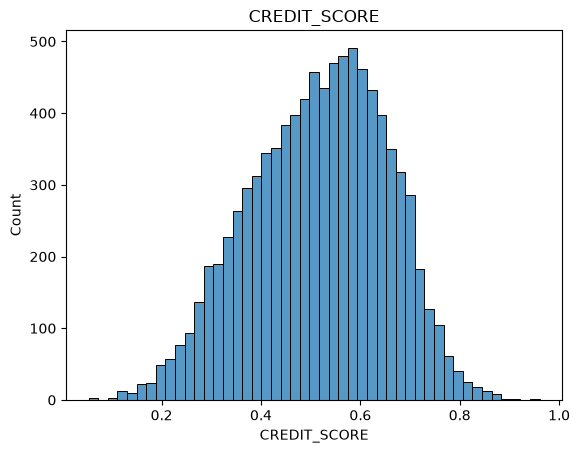

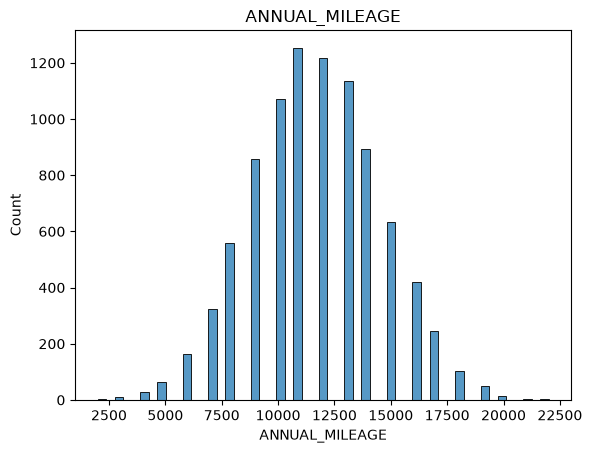

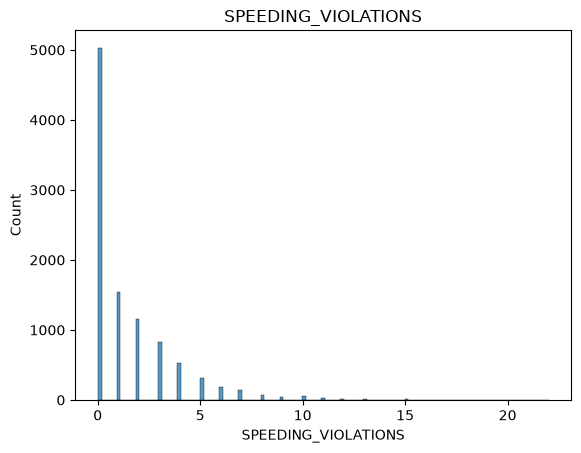

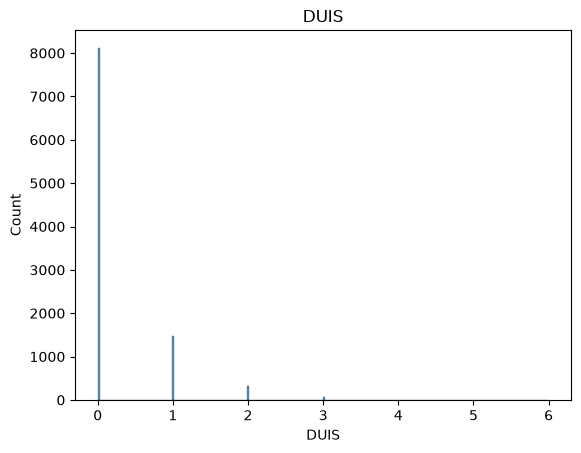

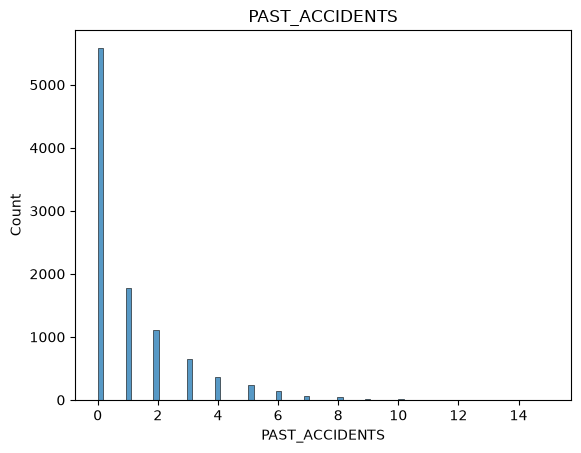

In [ ]:
# The 5 columns that will hold numbers
number_columns = ["CREDIT_SCORE", "ANNUAL_MILEAGE", "SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]

display(df[number_columns].describe().round(2))

# Skew for each column (0 = even, above 1 = lopsided)
display(df[number_columns].skew().round(2))


for column in number_columns:
    sns.histplot(df[column])
    plt.title(column)
    plt.show()

**What this shows:**
- `CREDIT_SCORE` and `ANNUAL_MILEAGE` are balanced (skew -0.23 and 0.04). Most customers are around the middle, and the mean and median are almost the same (0.52 vs 0.53, and 11,697 vs 12,000 miles).
- `SPEEDING_VIOLATIONS`, `DUIS` and `PAST_ACCIDENTS` are lopsided (skew above 2). Most customers have 0, but a few have a lot: up to 22 speeding violations, 6 DUIs and 15 accidents.


- What I learned performing these tasks is that the mean can be misleading when a column is lopsided. 'SPEEDING_VIOLATIONS' has a mean of 1.48 but a median of 0, so the typical customer has no violations. A few customers with very high values pull the average up

- The two columns with missing values (`CREDIT_SCORE` and `ANNUAL_MILEAGE`) are both even, so the mean and median are almost the same. I will use the median to fill the gaps, as it is safe either way.
- I will check the very high values in `SPEEDING_VIOLATIONS`, `DUIS` and `PAST_ACCIDENTS` as possible outliers in the Data Quality Report.



### Question 4 : Do drivers with past accidents seem to claim more ? 

I would expect drivers who have had accidents before to be more likely to claim again. I want to check if the data possibly shows this , becuase the column PAST_ACCIDENTS could be a useful input for the model when i continue making it 



PAST_ACCIDENTS
0    47.0
1    15.0
2    13.0
3     8.5
4     7.4
5     3.3
Name: OUTCOME, dtype: float64

PAST_ACCIDENTS
0    5584
1    1783
2    1104
3     646
4     366
5     517
Name: count, dtype: int64

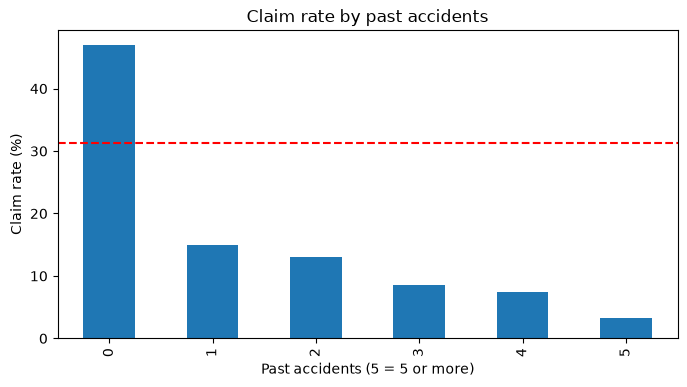

In [ ]:

overall_rate = df["OUTCOME"].mean() * 100   
accidents = df["PAST_ACCIDENTS"].clip(upper=5)


accident_rate = df.groupby(accidents)["OUTCOME"].mean() * 100
display(accident_rate.round(1))

# How many customers in each group
display(accidents.value_counts().sort_index())

accident_rate.plot(kind="bar", figsize=(8, 4))
plt.axhline(overall_rate, color="red", linestyle="--")
plt.ylabel("Claim rate (%)")
plt.xlabel("Past accidents (5 = 5 or more)")
plt.title("Claim rate by past accidents")
plt.show()

**What these results Show**
Drivers with 0 past accidents claim over 47% which is will above at average and average is shown with the red line to be at 31.3%
The claim rate based on this graph seems to go down as past accidents go up 

This is completly the opposite of what i expected because drivers who have been in past accidents generally are seen as higher risk 
A possible reason could be the driving expierience . All drivers aged 16-25 have 0 past accidents because they have not been driving long and this group shows to have claimed the most (71.8%)

I cant really say that past accidents make people likly to claim. This is a link in the data but not a cause.
In Question 5 i will compare drivers with the same driving exipierence to check this


## Question 5 : Do drivers with past accidents and same expierience Claim more than those who dont ?


PAST_ACCIDENTS,False,True
DRIVING_EXPERIENCE,,
0-9y,62.8,NaN
10-19y,26.0,22.2
20-29y,5.8,5.0
30y+,4.3,1.5


PAST_ACCIDENTS,False,True
DRIVING_EXPERIENCE,,
0-9y,3530,0
10-19y,1431,1868
20-29y,485,1634
30y+,138,914


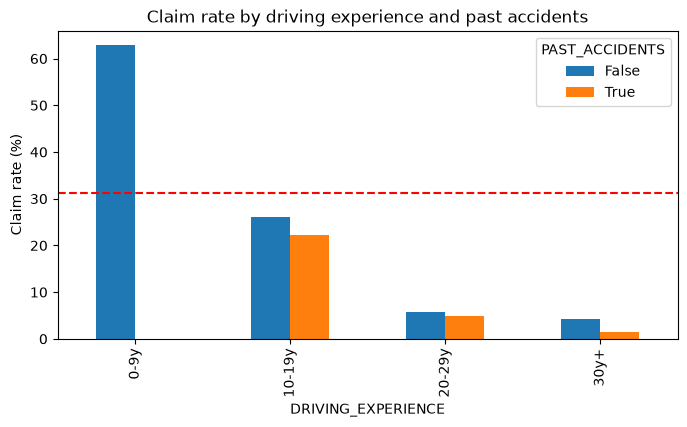

In [ ]:

has_accident = df["PAST_ACCIDENTS"] > 0


accident_table = pd.crosstab(df["DRIVING_EXPERIENCE"], has_accident,
                             values=df["OUTCOME"], aggfunc="mean") * 100
display(accident_table.round(1))


display(pd.crosstab(df["DRIVING_EXPERIENCE"], has_accident))

accident_table.plot(kind="bar", figsize=(8, 4))
plt.axhline(overall_rate, color="red", linestyle="--")
plt.ylabel("Claim rate (%)")
plt.title("Claim rate by driving experience and past accidents")
plt.show()

**What these Show**
- New drivers (0-9y) all have 0 past accidents so they cant be compared
- In other groups drivers with accidents dont claim more ,they actually seem to claim and bit less as years of expierence increase
  10-19y 22.2% vs 26.0%, 20-29y 5.0% vs 5.8%, 30y+ 1.5% vs 4.3%.
- Experience makes a bigger difference than accidents as drivers who have been drivng more are likly to expierence them vs those who have less experience decrease the chance  (62.8% for 0-9y , down to 6% for 20+y)


So the Question 4 pattern was mostly because of new drivers, who all have 0 accidents and claim the most.
It is strange that no new driver has had an accident, so I will note this in the Data Quality Report.

Due to this descion i will choose not to use `PAST_ACCIDENTS` in the model. even with the same expierence drivers with accidents are seen to claim less in this data . A model to be using this terminology would give lower risk to drivers with more accidents , I will chose to remove this in the Data preperation and record it in the preperation log



## 2.4 Data Quality Report

### Missing values
**Reason for checking this:** In 1.6. I assumed that CREDIT_SCORE and ANNUAL_MILEAGE are missing at random.
So then now i need to check this before filling them, because if the gaps belong to a certain type of customer, filling them could potentially add bias


In [4]:
# How many values are missing in each column
missing = df.isnull().sum()
print(missing)

# The same thing as a percentage
missing_percent = df.isnull().mean() * 100
print(missing_percent.round(1))

# How many customers are missing both columns
missing_both = df["CREDIT_SCORE"].isnull() & df["ANNUAL_MILEAGE"].isnull()
print("Missing both:", missing_both.sum())

# Claim rate for customers with a credit score (False) and without one (True)
credit_missing = df["CREDIT_SCORE"].isnull()
print((df.groupby(credit_missing)["OUTCOME"].mean() * 100).round(1))

# Same check for mileage
mileage_missing = df["ANNUAL_MILEAGE"].isnull()
print((df.groupby(mileage_missing)["OUTCOME"].mean() * 100).round(1))

ID                       0
AGE                      0
GENDER                   0
RACE                     0
DRIVING_EXPERIENCE       0
EDUCATION                0
INCOME                   0
CREDIT_SCORE           982
VEHICLE_OWNERSHIP        0
VEHICLE_YEAR             0
MARRIED                  0
CHILDREN                 0
POSTAL_CODE              0
ANNUAL_MILEAGE         957
VEHICLE_TYPE             0
SPEEDING_VIOLATIONS      0
DUIS                     0
PAST_ACCIDENTS           0
OUTCOME                  0
dtype: int64
ID                     0.0
AGE                    0.0
GENDER                 0.0
RACE                   0.0
DRIVING_EXPERIENCE     0.0
EDUCATION              0.0
INCOME                 0.0
CREDIT_SCORE           9.8
VEHICLE_OWNERSHIP      0.0
VEHICLE_YEAR           0.0
MARRIED                0.0
CHILDREN               0.0
POSTAL_CODE            0.0
ANNUAL_MILEAGE         9.6
VEHICLE_TYPE           0.0
SPEEDING_VIOLATIONS    0.0
DUIS                   0.0
PAST_ACCIDENTS 

**What these Show**

Only CREDIT_SCORE (9.8%) and ANNUAL_MILEAGE (9.6%) have gaps. 88 customers are missing both, which is about what you’d expect by chance (~94), so the gaps aren’t linked. Customers with gaps claim at nearly the same rate, so the assumption in 1.6 looks OK. I can’t be sure why they’re missing, as Kaggle doesn’t say. I’ll fill them with the median from the training data in Data Preparation.

### Duplicates,Invalid values, categories and units

**Why I'm checking this:** Duplicate customers would be counted twice, and impossible values would
be errors to fix before modelling.

In [5]:
# Any rows that appear twice?
print("Duplicate rows:", df.duplicated().sum())

# Any customer ID used twice?
print("Duplicate IDs:", df["ID"].duplicated().sum())

# These columns should only hold 0 or 1
print("VEHICLE_OWNERSHIP:", df["VEHICLE_OWNERSHIP"].unique())
print("MARRIED:", df["MARRIED"].unique())
print("CHILDREN:", df["CHILDREN"].unique())
print("OUTCOME:", df["OUTCOME"].unique())

# Lowest value in each count column (should not be below 0)
print(df[["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]].min())

# Credit score should be between 0 and 1
print("Lowest credit score:", df["CREDIT_SCORE"].min().round(2))
print("Highest credit score:", df["CREDIT_SCORE"].max().round(2))

# checking if the Age isnt lower than the driving expierience as AI pointed it to me i should add it 
print(pd.crosstab(df["AGE"], df["DRIVING_EXPERIENCE"]))

Duplicate rows: 0
Duplicate IDs: 0
VEHICLE_OWNERSHIP: [1. 0.]
MARRIED: [0. 1.]
CHILDREN: [1. 0.]
OUTCOME: [0. 1.]
SPEEDING_VIOLATIONS    0
DUIS                   0
PAST_ACCIDENTS         0
dtype: int64
Lowest credit score: 0.05
Highest credit score: 0.96
DRIVING_EXPERIENCE  0-9y  10-19y  20-29y  30y+
AGE                                           
16-25               2016       0       0     0
26-39                683    2380       0     0
40-64                533     587    1811     0
65+                  298     332     308  1052


**What these show**

No duplicates or impossible values were found, so nothing needs fixing here. The category spellings were already checked in 2.2 and are consistent. Two things I can’t check: ANNUAL_MILEAGE has no unit (I assume miles because the data is from the US) and the CREDIT_SCORE scale isn’t explained. The 0/1 columns are stored as decimals, so I’ll change them to whole numbers in Data Preparation

### Outliers and unusual values
**Why I'm checking this:** In Q3 the count columns had a few very high values. I need to decide if
they are mistakes or real customers. I also found two strange patterns earlier (postal codes in Q1
and new drivers in Q5) that I need to check.

In [17]:


for column in ["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]:
    q1 = df[column].quantile(0.25)          
    q3 = df[column].quantile(0.75)          
    upper_limit = q3 + 1.5 * (q3 - q1)      
    outliers = (df[column] > upper_limit).sum()
    print(column, "- limit:", upper_limit, "- outliers:", outliers)


# Highest value in each age group
df.groupby("AGE")[["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]].max()

# How many customers in each postal code, and their claim rate

display(df["POSTAL_CODE"].value_counts())
(df.groupby("POSTAL_CODE")["OUTCOME"].mean() * 100).round(1)

# Only the 0-9y drivers, then their highest value - 0 means none of them have any

new_drivers = df[df["DRIVING_EXPERIENCE"] == "0-9y"]
new_drivers[["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"]].max()

SPEEDING_VIOLATIONS - limit: 5.0 - outliers: 588
DUIS - limit: 0.0 - outliers: 1882
PAST_ACCIDENTS - limit: 5.0 - outliers: 285


POSTAL_CODE
10238    6940
32765    2456
92101     484
21217     120
Name: count, dtype: int64

SPEEDING_VIOLATIONS    0
DUIS                   0
PAST_ACCIDENTS         0
dtype: int64

**What these show**

- The IQR rule finds 588 speeding , 1882 DUI and 285 accident outliers. For DUIS the limit is 0 because most poeple have none so even 1 DUI counts as a outlier but the rule doesnt suit this kind of data

- This is how mant customers live in each area most are in 10238 21217 is tiny with only 120
- the Second box is the % of customers in each area who claimed, Three areas are between 27% and 41%. this is normal next to the 31.3% on average , But 21217 is 100% which means every single one of the 120 customers claimed and this shows this is not realistic, A model would learn if u live in 21217 'you will claim' which is a complete fake rule

- all zero, but in real life at least some new drivers would have a fine or an accident. This suggests the data was partly generated. I can’t fix this, so I will list it as a limitation, as the model may not work the same on real insurance data.